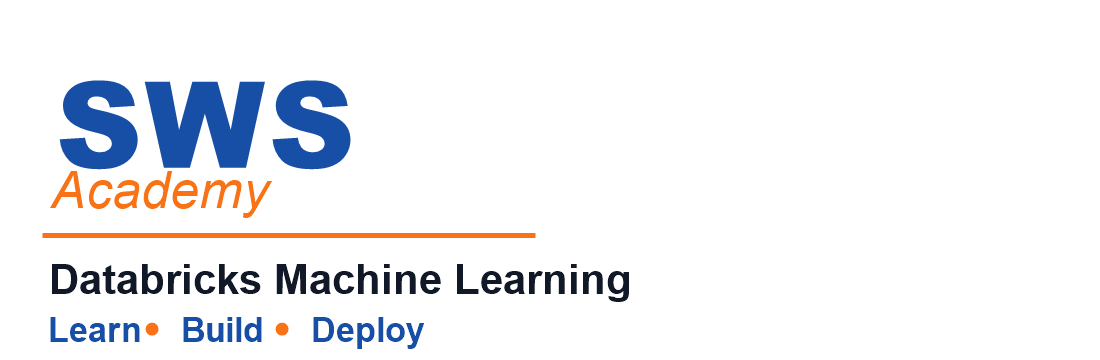

# Scalable Model Training with Ray Train and PyTorch (Airbnb Tabular Regression)

This notebook demonstrates how to perform **scalable, distributed model training** using [Ray Train](https://docs.ray.io/en/latest/train/train.html), [PyTorch](https://pytorch.org/), and [MLflow](https://mlflow.org/) on Databricks, applied specifically to **structured/tabular Airbnb data** for regression tasks.

In contrast to computer vision workflows (such as CNN-based image classification), this notebook focuses on **general-purpose distributed model training**, where Ray Train is used to scale **tabular regression** across any compute configuration. The techniques shown here apply equally well to classification, forecasting, feature-based modeling, and other structured ML workloads.

Ray Train abstracts away the complexity of distributed systems, allowing training to scale efficiently from a single machine to multi-node clusters, using either CPUs or GPUs. Integration with MLflow ensures complete experiment tracking, reproducibility, and smooth collaboration across teams.

**Why Use Ray Train?**

- **Scale any ML workload seamlessly**, including tabular regression, tabular classification, tree models, neural networks, and custom pipelines.
- **Run on CPUs or GPUs** with automatic distributed coordination across workers.
- **Support for multiple frameworks**, including PyTorch, TensorFlow, HuggingFace Transformers, XGBoost, LightGBM, and more.
- **Native sharded data ingestion** from Ray Datasets for efficient loading of large tabular datasets.
- **Built-in experiment tracking** via MLflow with metrics, parameters, checkpoints, and artifacts.

Distributed, scalable training is particularly beneficial when working with:

- Large or high-dimensional tabular datasets
- Complex or deep models requiring iterative experimentation
- Long-running experiments where fault tolerance and checkpointing are required
- Training pipelines that must be production-ready and reproducible

**Learn More:**

- [Ray Train Overview](https://docs.ray.io/en/latest/train/overview.html)  
- [Integrating Ray Train with MLflow](https://docs.databricks.com/machine-learning/ray/ray-mlflow)

**Learning Objectives**

By the end of this notebook, you will be able to:

- **Initialize and configure a Ray runtime** on Databricks to support distributed training.
- **Preprocess Airbnb tabular data** and convert it into a **Ray Dataset** for parallelized batch loading.
- **Define a Ray Train–compatible training loop** that includes loss computation, optimization, validation, metric reporting, and checkpointing.
- **Launch distributed training jobs** with `TorchTrainer`, using CPU or GPU workers, and later log evaluation metrics and model artifacts with MLflow.
- **Monitor training progress** using Ray's reporting API and exported TensorBoard logs.
- **Evaluate the final model** using regression metrics such as RMSE, MAE, and R² on a held-out test split.
- **Log all metrics, hyperparameters, and artifacts to MLflow**, ensuring experiment reproducibility and auditability.
- **(Optional)**: Register and version your trained PyTorch model in **Unity Catalog** using MLflow for governed deployment and inference.

**Appendix**

- **Monitoring and Observability**: Learn how to inspect distributed job execution, worker health, cluster load, and system logs using the Ray Dashboard (when available in the environment).  
- **TensorBoard Integration**: Visualize training curves, loss trends, and performance metrics using TensorBoard logs generated during the Ray Train run.

## REQUIRED - SELECT CLASSIC COMPUTE
Before executing cells in this notebook, please select your classic compute cluster in the lab. Be aware that **Serverless** is enabled by default.

Follow these steps to select the classic compute cluster:
1. Navigate to the top-right of this notebook and click the drop-down menu to select your cluster. By default, the notebook will use **Serverless**.

1. If your cluster is available, select it and continue to the next cell. If the cluster is not shown:
    - In the drop-down, select **More**.
    - In the **Attach to an existing compute resource** pop-up, select the first drop-down. You will see a unique cluster name in that drop-down. Please select that cluster.

**NOTE:** If your cluster has terminated, you might need to restart it in order to select it. To do this:

1. Right-click on **Compute** in the left navigation pane and select *Open in new tab*.

1. Find the triangle icon to the right of your compute cluster name and click it.
1. Wait a few minutes for the cluster to start.
1. Once the cluster is running, complete the steps above to select your cluster.

## Requirements

Please review the following requirements before starting the lesson:

- To run this notebook, you need to use one of the following Databricks runtime(s): `16.4.x-cpu-ml-scala2.12`

##Classroom Setup

Run the following cell to configure your working environment for this course. It will also set your default catalog to **swsacademy** and the schema to your specific schema name shown below using the `USE` statements.
<br></br>


```
USE CATALOG swsacademy;
USE SCHEMA swsacademy.<your unique schema name>;
```

**NOTE:** The `SA` object is only used in SWSAcademy courses and is not available outside of these courses. It will dynamically reference the information needed to run the course.

In [ ]:
%pip install "mlflow>=3.0" "pyopenssl>=24.2.1" "ray[default,tune]>=2.3.0" tensorboard databricks-feature-engineering
dbutils.library.restartPython()

In [ ]:
%run ../Includes/Classroom-Setup-03.2

**Other Conventions:**

Throughout this demo, we'll refer to the object `SA`. This object, provided by SWSAcademy, contains variables such as your username, catalog name, schema name, working directory, and dataset locations. Run the code block below to view these details:

In [ ]:
print(f"Username:          {SA.username}")
print(f"Catalog Name:      {SA.catalog_name}")
print(f"Schema Name:       {SA.schema_name}")
print(f"Working Directory: {SA.paths.working_dir}")

## Define Scalable Training Function for Ray Train

In this section, we define the **distributed training function** used by Ray Train’s `TorchTrainer` to enable scalable model training on **tabular Airbnb data**.  
This function encapsulates the entire end-to-end workflow required to train, validate, and checkpoint a PyTorch model across multiple Ray workers running in parallel.

Ray Train orchestrates distributed execution through the following mechanisms:

- **Worker Distribution:**  
  The training function is executed independently on each Ray worker. Each worker receives its own dataset shard, ensuring efficient utilization of distributed compute resources.

- **Ray Data Integration:**  
  By calling `train.get_dataset_shard("train")`, Ray automatically partitions the dataset so that each worker operates on a unique, non-overlapping subset. This eliminates manual data partitioning and ensures consistent scaling behavior.

- **Model Training Logic:**  
  Every worker performs the standard PyTorch training loop, including forward propagation, loss computation, backward propagation, and gradient updates.  
  For tabular data, a lightweight fully connected network (MLP) is typically used, but this structure is entirely customizable.

- **Validation Loop:**  
  At the end of each epoch, each worker evaluates the model on its validation shard using the same PyTorch evaluation logic.  
  Depending on the task, metrics such as **validation loss, RMSE, MAE, accuracy**, or custom-defined metrics can be computed.

- **Metric Reporting and Checkpointing:**  
  Workers report metrics back to the Ray driver using `train.report()`.  
  Ray aggregates these updates and tracks progress across epochs.  
  The best-performing model state is saved to a checkpoint, allowing it to be reloaded for inference or registered in MLflow.

This training function is intentionally designed to be **general-purpose**, **framework-agnostic**, and **dataset-agnostic**, allowing it to scale:

- Tabular regression or classification
- Text/NLP models
- Image models (CNNs)
- Any custom PyTorch architecture

It provides a unified abstraction for distributed training that works consistently across CPU- and GPU-based clusters.

> **Important:**  
> Although this notebook demonstrates the function using Airbnb tabular data, the same structure applies to any PyTorch model. Simply replace the model architecture or loss function to adapt the workflow to new tasks.

### Training Function: Core Steps and Logic

The **training function** is the central component of any Ray Train workflow. It defines the full set of operations that each Ray worker executes during distributed training.

When using `TorchTrainer` (or any Ray Train trainer), Ray automatically:

- Launches this function on each worker in parallel.
- Assigns a distinct **shard** of the dataset to every worker.
- Collects and aggregates metrics reported by workers throughout training.

This enables scalable, fault-tolerant, and fully parallel model training.

**Core Phases Inside the Training Function**

**1. Setup and Initialization**
- Detect and select the appropriate compute device (`CPU` or `GPU`).
- Initialize the model architecture (for tabular data, typically an MLP) and move it to the selected device.
- Initialize the optimizer (e.g., Adam) and appropriate loss function:
  - `MSELoss` for regression
  - `BCEWithLogitsLoss` for binary classification
  - `CrossEntropyLoss` for multi-class classification
- Optionally set up a TensorBoard `SummaryWriter` on `rank 0` for logging training curves.

**2. Validation Data Preparation**
- Load the validation dataset shard using `train.get_dataset_shard("val")` if provided.
- Convert batches of validation features and labels into tensors.
- Compute evaluation metrics such as RMSE, MAE, or accuracy depending on the task.
- Keep track of the best validation metric during training.

**3. Access the Worker’s Dataset Shard**
- Each worker retrieves its assigned portion of the training data using:

  ```python
  train.get_dataset_shard("train")
  ```

  The worker processes only its shard, enabling parallelism without manual data partitioning.
- Ray Data automatically handles shuffling, batching, and efficient data loading.

**4. Epoch Loop**
- For each epoch, the function performs two major phases:

  **Training Phase**
  - Iterate over batches from the worker's training shard.
  - Convert each batch's tabular feature vectors and labels into tensors.
  - Run forward propagation, compute loss, backpropagate gradients, and update parameters.
  - Accumulate average training loss per epoch.

  **Validation Phase**
  - After each epoch, evaluate the model using the validation shard:
    - Compute loss
    - Compute accuracy or other task-specific metrics
    - Determine whether the current model is the best so far and store its weights.

**5. Metric Reporting**
- Report metrics to Ray using `train.report()`, such as:
  - `epoch`
  - `train_loss`
  - `val_loss`
  - `val_accuracy` (classification)
  - `best_metric` (best loss or best accuracy so far)
- Reported metrics appear in:
  - Ray Train logs
  - MLflow experiment runs (if enabled)
  - TensorBoard (via SummaryWriter)
  - Ray Dashboard (if accessible)
- This enables real-time monitoring of training progress.

**6. Checkpointing**
- Save the best model weights to a temporary directory once training completes.
- Wrap the saved artifacts into a Ray Checkpoint object.
- Return the checkpoint so it can be:
  - Loaded for evaluation
  - Logged or registered with MLflow
  - Promoted for batch inference or deployment pipelines

In [ ]:
def ray_train_tabular_loop(config):
    from ray import train
    from ray.train import Checkpoint, get_context
    import torch
    import torch.nn as nn
    import torch.optim as optim
    import tempfile
    import os
    from torch.utils.tensorboard import SummaryWriter

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # 1. Read config
    input_dim_cfg = config.get("input_dim", None)
    task_type = config.get("task_type", "regression")
    num_classes = config.get("num_classes", None)
    tb_logdir = config.get("tb_logdir", None)

    # Set up TensorBoard writer for rank 0 only
    ctx = get_context()
    world_rank = ctx.get_world_rank() if ctx is not None else 0
    writer = None
    if tb_logdir and world_rank == 0:
        writer = SummaryWriter(log_dir=tb_logdir)

    # 2. Choose output dim, loss function, and metric direction
    if task_type == "regression":
        output_dim = 1
        loss_fn = nn.MSELoss()
        higher_is_better = False  # minimize val_loss
    elif task_type == "binary_classification":
        output_dim = 1
        loss_fn = nn.BCEWithLogitsLoss()
        higher_is_better = True   # maximize accuracy
    else:  # multi-class classification
        if num_classes is None:
            raise ValueError("num_classes must be provided for multi-class classification.")
        output_dim = num_classes
        loss_fn = nn.CrossEntropyLoss()
        higher_is_better = True

    # 3. Simple MLP model for tabular data (lazy init after first batch)
    class MLP(nn.Module):
        def __init__(self, input_dim, output_dim):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(input_dim, 64),
                nn.ReLU(),
                nn.Linear(64, 32),
                nn.ReLU(),
                nn.Linear(32, output_dim),
            )

        def forward(self, x):
            return self.net(x)

    model = None
    optimizer = None
    effective_input_dim = None  # will be set from first batch

    # 4. Get Ray Dataset shards
    train_shard = train.get_dataset_shard("train")
    try:
        val_shard = train.get_dataset_shard("val")
        has_val = True
    except Exception:
        val_shard = None
        has_val = False

    # 5. Training loop
    best_metric = float("inf") if not higher_is_better else float("-inf")
    best_val_loss = None
    best_model_state = None

    for epoch in range(config["epochs"]):
        # Training
        epoch_loss = 0.0
        num_batches = 0

        for batch in train_shard.iter_torch_batches(
            batch_size=config["batch_size"],
            dtypes={"features": torch.float32, "label": torch.float32},
        ):
            X = batch["features"].to(device)
            y = batch["label"].to(device)

            # Lazily build the model after we know feature dimension
            if model is None:
                effective_input_dim = X.shape[1]

                # Validate input_dim if provided in config
                if input_dim_cfg is not None and input_dim_cfg != effective_input_dim:
                    if writer is not None:
                        writer.close()
                    raise ValueError(
                        f"Configured input_dim={input_dim_cfg}, "
                        f"but dataset features have dimension {effective_input_dim}."
                    )

                model = MLP(input_dim=effective_input_dim, output_dim=output_dim).to(device)
                optimizer = optim.Adam(model.parameters(), lr=config["lr"])

            if task_type == "regression":
                y = y.view(-1, 1)
            elif task_type == "binary_classification":
                y = y.view(-1, 1)
            else:
                y = y.long().view(-1)

            model.train()
            optimizer.zero_grad()
            preds = model(X)
            loss = loss_fn(preds, y)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            num_batches += 1

        avg_train_loss = epoch_loss / max(num_batches, 1) if num_batches > 0 else None

        # Validation
        val_metric = None
        val_loss = None

        if has_val and model is not None:
            model.eval()
            val_epoch_loss = 0.0
            val_batches = 0
            correct = 0
            total = 0

            with torch.no_grad():
                for batch in val_shard.iter_torch_batches(
                    batch_size=config.get("val_batch_size", 256),
                    dtypes={"features": torch.float32, "label": torch.float32},
                ):
                    X = batch["features"].to(device)
                    y = batch["label"].to(device)

                    if task_type == "regression":
                        y = y.view(-1, 1)
                    elif task_type == "binary_classification":
                        y = y.view(-1, 1)
                    else:
                        y = y.long().view(-1)

                    outputs = model(X)
                    loss = loss_fn(outputs, y)
                    val_epoch_loss += loss.item()
                    val_batches += 1

                    if task_type in ("binary_classification", "classification"):
                        if task_type == "binary_classification":
                            preds = (torch.sigmoid(outputs) > 0.5).long().view(-1)
                            targets = y.view(-1).long()
                        else:
                            preds = outputs.argmax(dim=1)
                            targets = y
                        correct += (preds == targets).sum().item()
                        total += targets.size(0)

            if val_batches > 0:
                val_loss = val_epoch_loss / val_batches

                if task_type == "regression":
                    val_metric = val_loss
                else:
                    val_accuracy = correct / total if total > 0 else 0.0
                    val_metric = val_accuracy

                # Track best metric & best val_loss
                if val_metric is not None:
                    if higher_is_better:
                        is_better = val_metric > best_metric
                    else:
                        is_better = val_metric < best_metric

                    if is_better:
                        best_metric = val_metric
                        best_model_state = model.state_dict()
                        if task_type == "regression":
                            best_val_loss = val_loss

        # Report to Ray
        report_dict = {
            "epoch": epoch,
            "train_loss": avg_train_loss,
            "task_type": task_type,
            "best_metric": best_metric,
        }
        if val_loss is not None:
            report_dict["val_loss"] = val_loss
        if best_val_loss is not None and task_type == "regression":
            report_dict["best_val_loss"] = best_val_loss
        if task_type in ("binary_classification", "classification") and val_metric is not None:
            report_dict["val_accuracy"] = val_metric

        train.report(report_dict)

        # TensorBoard logging (rank 0)
        if writer is not None:
            if avg_train_loss is not None:
                writer.add_scalar("loss/train", avg_train_loss, epoch)
            if val_loss is not None:
                writer.add_scalar("loss/val", val_loss, epoch)
            if task_type in ("binary_classification", "classification") and val_metric is not None:
                writer.add_scalar("metrics/val_accuracy", val_metric, epoch)
            elif task_type == "regression" and best_val_loss is not None:
                writer.add_scalar("metrics/best_val_loss", best_val_loss, epoch)

    # 6. Final checkpoint with best model
    if model is None:
        if writer is not None:
            writer.close()
        raise RuntimeError("No training batches were processed; model was never built.")

    if best_model_state is None:
        # Fallback: save last model if no validation improvement was tracked
        best_model_state = model.state_dict()

    with tempfile.TemporaryDirectory() as tmpdir:
        save_path = os.path.join(tmpdir, "model_state_dict.pt")
        torch.save(best_model_state, save_path)
        checkpoint = Checkpoint.from_directory(tmpdir)
        train.report(
            {
                "best_metric": best_metric,
                "best_val_loss": best_val_loss,
                "task_type": task_type,
            },
            checkpoint=checkpoint,
        )

    if writer is not None:
        writer.close()

### Converting Training Data into a Ray Dataset

Before launching distributed training with **Ray Train**, our input data must be converted into a **Ray Dataset** — Ray’s native, distributed data abstraction.  
This format allows Ray to automatically **shard** the dataset across worker nodes, so each worker processes its own subset in parallel.

**Why Use Ray Datasets for Training?**

- **Distributed Sharding:** Each Ray worker receives a unique shard of the data (`train.get_dataset_shard("train")`), ensuring balanced parallel processing.  
- **Scalability:** Efficiently handles large tabular datasets across CPUs and GPUs.  
- **Interoperability:** Works natively with `TorchTrainer`, `TensorflowTrainer`, and all Ray Train APIs.  


**Implementation Steps**

1. **Convert Spark DataFrame or Pandas DataFrame to Ray-Compatible Format**  
   - Extract features and labels from the Airbnb dataset (e.g., `bedrooms`, `bathrooms`, `accommodates`, `availability_365`, etc.).
   - Each record should be a dictionary:  
     ```python
     {
       "features": [<list_of_numeric_features>],
       "label": <integer_or_float_label>
     }
     ```
     This structure is lightweight, serializable, and ideal for Ray Datasets.

2. **Create a Ray Dataset**  
   - Use `ray.data.from_pandas()` or `ray.data.from_items()` to convert your prepared data into a distributed Ray Dataset object:  
     ```python
     import ray
     ray_ds = ray.data.from_pandas(train_df)
     ```
     or if you’ve preprocessed features and labels manually:  
     ```python
     ray_ds = ray.data.from_items(prepared_records)
     ```

3. **Inspect the Dataset**  
   - Check the total record count and inspect a sample:  
     ```python
     print(ray_ds.count())
     print(ray_ds.take(1))
     ```
   - Each record should contain a flattened feature list and its corresponding label.


> 💡 **Tip:** Ray Datasets seamlessly integrate with PyTorch and TensorFlow trainers.  
> When you launch training with `TorchTrainer`, Ray automatically shards this dataset so that each worker node gets its own training subset — no manual splitting required.

In [ ]:
# Convert Spark DataFrames → Ray Datasets for tabular training
import os
import ray
import numpy as np
from ray.data import from_items

# Start Ray before the first Ray Dataset call. On a single-node cluster the Spark driver keeps most of the machine's
# memory, which Ray counts as used and then kills its own workers at 95%. For this small demo, switch off that
# memory-based killing, keep Ray's object store small, and give Ray a fixed memory budget for its tasks
# (otherwise Ray works out "free memory" itself and can find none while the Spark driver holds it).
if not ray.is_initialized():
    import inspect
    os.environ["RAY_memory_monitor_refresh_ms"] = "0"
    init_args = {"object_store_memory": 500_000_000, "ignore_reinit_error": True}
    init_params = inspect.signature(ray.init).parameters
    for name in ("_memory", "memory"):          # the task-memory setting is called _memory in Ray 2.x
        if name in init_params:
            init_args[name] = 2_000_000_000
            break
    ray.init(**init_args)

def spark_to_ray_dataset(sdf, feature_cols, label_col):
    """
    Convert a Spark DataFrame into a Ray Dataset with
    columns: 'features' (np.array) and 'label' (float/int).
    """
    if not feature_cols:
        raise ValueError(
            "feature_cols is empty in spark_to_ray_dataset. "
            "Make sure feature_cols is defined and non-empty before calling this."
        )

    # Bring selected columns to Pandas
    pdf = sdf.select(*(feature_cols + [label_col])).toPandas()

    # Vectorized conversion to numpy arrays
    feat_array = pdf[feature_cols].to_numpy(dtype=np.float32)
    labels = pdf[label_col].to_numpy(dtype=np.float32)

    # Build list of dicts for Ray
    items = [
        {"features": x, "label": y}
        for x, y in zip(feat_array, labels)
    ]
    return from_items(items)

# Create Ray Datasets
train_ray_dataset = spark_to_ray_dataset(train_sdf, feature_cols, "label")
val_ray_dataset   = spark_to_ray_dataset(val_sdf,   feature_cols, "label")
test_ray_dataset  = spark_to_ray_dataset(test_sdf,  feature_cols, "label")

# Basic stats
print(f"Train Ray Dataset Row Count: {train_ray_dataset.count()}")
print("Train Sample Row:", train_ray_dataset.take(1)[0])

print(f"Val Ray Dataset Row Count: {val_ray_dataset.count()}")
print("Val Sample Row:", val_ray_dataset.take(1)[0])

print(f"Test Ray Dataset Row Count: {test_ray_dataset.count()}")
print("Test Sample Row:", test_ray_dataset.take(1)[0])


**Explanation**
- **Distributed Execution:** Ray launches the `ray_train_tabular_loop` function on one or more workers and automatically shards the Ray Dataset, so each worker trains on its own subset of the data.
- **Model Updates:** Each worker runs a standard PyTorch training loop (forward pass, loss computation, backpropagation, optimizer step) on its shard of tabular Airbnb features and labels.
- **Validation and Reporting:** After each epoch, the model is evaluated on the validation shard. For regression tasks, validation loss is computed; for classification tasks, accuracy can be computed. Metrics are reported to Ray using `train.report()`.
- **Checkpointing:** The best model state (based on the chosen metric) is saved to a Ray `Checkpoint`, which you later reload for test-time evaluation and MLflow/Unity Catalog registration.
- **Scalability:** The loop is generic enough to support regression or classification on tabular data, and can be extended to other PyTorch architectures.

> In later steps, you will log **test-set regression metrics** and handle **model registration** with MLflow and Unity Catalog.

For more details on distributed training functions and configurations, see:
- [Ray Train - Distributed Training Docs](https://docs.ray.io/en/latest/train/train.html)
- [Ray Train: PyTorch Trainer API](https://docs.ray.io/en/latest/train/api/doc/ray.train.torch.TorchTrainer.html)
- [Best Practices in Ray Reporting and Distributed Experiment Tracking](https://docs.ray.io/en/latest/tune/tutorials/tune-distributed.html)

### Launch Distributed Training with Ray TorchTrainer

In this section, we launch our **distributed model training** workflow using Ray Train’s `TorchTrainer`.  
Ray orchestrates scalable training by launching one or more worker processes, automatically sharding the Ray Dataset, and aggregating training metrics for full experiment traceability.

**What Happens When You Launch TorchTrainer?**

- **Distributed Workers:**  
  Ray spawns the specified number of workers. Each worker executes the training loop independently on its own dataset shard.

- **Ray Dataset Integration:**  
  Training data is passed as a Ray Dataset, allowing Ray to automatically shard it across workers without manual splitting.

- **Custom Training Function:**  
  The `ray_train_tabular_loop` function (defined earlier) contains the full training, validation, and checkpointing logic that each worker executes.

- **Experiment Tracking:**  
  All metrics reported via `train.report()` are collected in the final `result` object.  
  In this notebook, you later log test-set metrics and register the model with MLflow and Unity Catalog.

- **Live Dashboard:**  
  (If available in the environment) the Ray Dashboard provides visibility into resources, tasks, and worker status during training.

**TorchTrainer Configuration Parameters**

- **ScalingConfig:**  
  - `num_workers`: Number of Ray worker processes to launch.  
  - `resources_per_worker`: CPU (and optional GPU) allocation per worker.  
  - `use_gpu`: Enables automatic GPU assignment if available.

- **Training Config (`train_loop_config`):**  
  - `input_dim`: Number of input features.  
  - `lr`: Learning rate for the optimizer.  
  - `batch_size`: Training batch size.  
  - `epochs`: Number of training epochs.  
  - `task_type`: Task type (e.g., `"regression"` or `"binary_classification"`).  
  - `tb_logdir`: Directory where TensorBoard logs will be written.

- **Datasets Argument:**  
  - `datasets={"train": train_ray_dataset, "val": val_ray_dataset}`  
    Ray automatically shards each dataset across workers.

- **RunConfig:**  
  - `name`: Experiment run name for organization and tracking.  
  - `storage_path`: Directory where checkpoints, logs, and Ray artifacts are saved.

In [ ]:
from ray.train.torch import TorchTrainer
from ray.train import ScalingConfig, RunConfig
import torch
import time
import os
import ray

# (Re)Initialize Ray cluster
ray.init(ignore_reinit_error=True)

# Define a TensorBoard log directory
tb_logdir = f"/local_disk0/tmp/ray_tabular_runs/tensorboard_{int(time.time())}"  # driver local disk (DBFS root may be disabled)

# Training configuration
train_config = {
    "input_dim": len(feature_cols),  # Number of input features
    "lr": 1e-3,                      # Learning rate
    "batch_size": 32,                # Batch size
    "epochs": 5,                     # Number of epochs
    "task_type": "regression",       # Regression task
    "tb_logdir": tb_logdir, # TensorBoard log directory
}

# Ray scaling configuration
scaling_config = ScalingConfig(
    num_workers=1,
    resources_per_worker={"CPU": 1},
    use_gpu=torch.cuda.is_available()
)

# Ray run configuration
run_config = RunConfig(
    name="ray_tabular_airbnb_regression",
    storage_path=f"/Volumes/{SA.catalog_name}/{SA.schema_name}/ray_logs/ray_tabular_runs"  # Unity Catalog volume
)

# Create and run Ray TorchTrainer
trainer = TorchTrainer(
    train_loop_per_worker=ray_train_tabular_loop,
    train_loop_config=train_config,
    scaling_config=scaling_config,
    datasets={"train": train_ray_dataset, "val": val_ray_dataset},
    run_config=run_config
)

print("Launching Ray TorchTrainer for distributed training...")
result = trainer.fit()
print("Training complete.")

# Summarize metrics
final_metrics = result.metrics or {}
print("\n=== Ray Result Metrics ===")
print("Best metric:", final_metrics.get("best_metric"))
print("Best validation loss (from result.metrics):", final_metrics.get("best_val_loss"))

# Get last and best validation loss from metrics dataframe
metrics_df = result.metrics_dataframe

if "val_loss" in metrics_df.columns:
    non_null_loss = metrics_df["val_loss"].dropna()
    last_val_loss = non_null_loss.iloc[-1] if not non_null_loss.empty else None
    best_val_loss_df = non_null_loss.min() if not non_null_loss.empty else None
else:
    last_val_loss = best_val_loss_df = None

# For TensorBoard visualization
experiment_log_dir = tb_logdir
print("\nExperiment log directory for TensorBoard:", experiment_log_dir)

**Explanation:**  
- The above code launches a distributed training job using Ray’s TorchTrainer.
- Training parameters, resource scaling, and experiment tracking are explicitly defined for reproducibility.
- After training (`trainer.fit()`), you can review key metrics and artifacts from the Ray `result` object and storage path. In later steps, final evaluation metrics and the registered model are captured in MLflow for tracking and governance.

> For further reading:  
> - [Ray TorchTrainer Documentation](https://docs.ray.io/en/latest/train/api/doc/ray.train.torch.TorchTrainer.html)  
> - [Ray ScalingConfig Reference](https://docs.ray.io/en/latest/train/api/doc/ray.train.ScalingConfig.html)  
> - [Ray Dashboard Guide](https://docs.ray.io/en/latest/ray-core/ray-dashboard.html)

### Evaluate the Trained Model on the Test Set (Regression Metrics)

In this step, we load the **best-performing Ray Train checkpoint**, rebuild the same PyTorch MLP architecture used during training, and run inference on the held-out Airbnb test data.  
This allows us to measure how well the model generalizes to unseen listings.

**What this cell does:**

- **Rebuilds the MLP architecture:**  
  The same fully connected network used during training is reconstructed so the trained weights can be loaded.

- **Loads the saved Ray checkpoint:**  
  The best model weights (captured during validation) are loaded from the `result.checkpoint` directory.

- **Runs inference on the test split:**  
  The model predicts values on the log-transformed target (`log1p(price)`), which are then converted back to the original price scale using `expm1()`.

- **Computes regression metrics** on:
  - **log-transformed scale:** RMSE, MAE, R²  
  - **original price scale:** RMSE, MAE, R²  

  Evaluating on both scales provides full insight into prediction stability and real-world interpretability.

- **Logs all test metrics to MLflow:**  
  RMSE, MAE, and R² (on both scales) are recorded for experiment comparison, auditability, and downstream analysis.

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import torch
import os
import mlflow

# Rebuild the MLP model used in training
class MLP(torch.nn.Module):
    def __init__(self, input_dim, output_dim=1):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(input_dim, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, output_dim),
        )

    def forward(self, x):
        return self.net(x)

# Prepare test data (Spark → Pandas → NumPy)
test_pdf = test_sdf.select(*(feature_cols + ["label", "price"])).toPandas()
X_test = test_pdf[feature_cols].to_numpy(dtype=np.float32)
y_test_log = test_pdf["label"].to_numpy(dtype=np.float32)
y_test_price = test_pdf["price"].to_numpy(dtype=np.float32)

print("Test shape:", X_test.shape)

# Load trained model from Ray checkpoint
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_dim = X_test.shape[1]
trained_model = MLP(input_dim=input_dim, output_dim=1).to(device)

if result.checkpoint is not None:
    with result.checkpoint.as_directory() as checkpoint_dir:
        model_path = os.path.join(checkpoint_dir, "model_state_dict.pt")
        model_state = torch.load(model_path, map_location=device)
        trained_model.load_state_dict(model_state)
else:
    raise ValueError("Checkpoint is None. Cannot load model state.")

trained_model.eval()

# Run inference on test set
with torch.no_grad():
    X_tensor = torch.from_numpy(X_test).to(device)
    preds_log = trained_model(X_tensor).view(-1).cpu().numpy()

# Convert predictions back to original price scale
y_pred_price = np.expm1(preds_log)
y_true_price = y_test_price

# Compute regression metrics
# Metrics on log1p(price)
rmse_log = mean_squared_error(y_test_log, preds_log, squared=False)
mae_log = mean_absolute_error(y_test_log, preds_log)
r2_log = r2_score(y_test_log, preds_log)

print("=== Test Metrics on log(price + 1) ===")
print(f"RMSE (log): {rmse_log:.4f}")
print(f"MAE  (log): {mae_log:.4f}")
print(f"R²   (log): {r2_log:.4f}")

# Metrics on original price scale
rmse_price = mean_squared_error(y_true_price, y_pred_price, squared=False)
mae_price = mean_absolute_error(y_true_price, y_pred_price)
r2_price = r2_score(y_true_price, y_pred_price)

print("\n=== Test Metrics on price (original scale) ===")
print(f"RMSE (price): {rmse_price:.2f}")
print(f"MAE  (price): {mae_price:.2f}")
print(f"R²   (price): {r2_price:.4f}")

# Log metrics to MLflow
mlflow.log_metric("test_rmse_log", float(rmse_log))
mlflow.log_metric("test_mae_log", float(mae_log))
mlflow.log_metric("test_r2_log", float(r2_log))

mlflow.log_metric("test_rmse_price", float(rmse_price))
mlflow.log_metric("test_mae_price", float(mae_price))
mlflow.log_metric("test_r2_price", float(r2_price))

### Optional Classification View: High-Price vs Low-Price Analysis

Although this is fundamentally a **regression task**, we can derive a simple binary classification view by thresholding the predicted prices.  
This helps reveal systematic over-predictions or under-predictions.

**What this cell does:**

- **Defines a binary label:**  
  The median true price is used as a threshold to categorize listings into:
  - `1` → high-price  
  - `0` → low-price  

- **Generates binary predictions:**  
  Model-predicted prices are thresholded in the same way to produce predicted labels.

- **Computes a confusion matrix:**  
  Visualized using a seaborn heatmap to understand:
  - True Positives (correctly predicted high price)  
  - True Negatives  
  - False Positives (over-predicted)  
  - False Negatives (under-predicted)

- **Displays a classification report:**  
  Includes precision, recall, F1-score, and support for the derived binary classes.

This view is not used for model training but provides **additional diagnostic insight** into where the regression model tends to over- or under-estimate price ranges.

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Create binary threshold for HIGH_PRICE (derived from regression)
price_threshold = np.median(y_true_price)

y_true_bin = (y_true_price > price_threshold).astype(int)
y_pred_bin = (y_pred_price > price_threshold).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_true_bin, y_pred_bin)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion Matrix (Threshold = {price_threshold:.2f})")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# Classification report
print("\nBinary Classification Report (derived from regression):")
print(classification_report(y_true_bin, y_pred_bin))

**What this achieves:**
- **Closes the ML loop:** from data → model training → evaluation → logging → explainability.
- Key regression metrics (RMSE, MAE, R² on both log-transformed and original price scales) are tracked in MLflow for comparison across runs and datasets.
- The derived binary classification view and confusion matrix visualization provide additional insight for tuning, troubleshooting, or reporting.

> **References:**
> - [sklearn.metrics: Classification Report & Confusion Matrix](https://scikit-learn.org/stable/modules/model_evaluation.html)
> - [MLflow Tracking API](https://mlflow.org/docs/latest/tracking.html)
> - [Ray Train Best Practices: Evaluation and Checkpoint Usage](https://docs.ray.io/en/latest/train/user-guides/results.html)

**Why this matters:**  
- Demonstrates an end-to-end workflow: **model is trained → registered → loaded from catalog → used for prediction on new data.**
- Confirms that your registered Unity Catalog model can be reliably deployed for inference using the exact same preprocessing and signature as during evaluation.
- This pattern supports production batch scoring, model serving, and can be plugged into scoring APIs or UI demos.

> **References:**
> - [MLflow PyTorch Model Loading](https://mlflow.org/docs/latest/python_api/mlflow.pytorch.html#mlflow.pytorch.load_model)
> - [Unity Catalog Models - Serving & Inference](https://docs.databricks.com/en/machine-learning/model-serving/inference.html)
> - [Using Registered Models in MLflow for Batch and Real-time](https://mlflow.org/docs/latest/model-registry.html)

## Conclusion

We've completed a full end-to-end workflow for scalable, distributed model training using **Ray Train**, **PyTorch**, and **MLflow** on Databricks. This notebook demonstrated not just the mechanics of distributed deep learning, but powerful patterns for experiment tracking, monitoring, and production model lifecycle management.

**Key Takeaways**

You have:

- **Initialized and configured a Ray runtime** on your Databricks cluster to support distributed training.
- **Prepared data and trained a general PyTorch model** in a distributed fashion using Ray Train's `TorchTrainer`.
- **Logged metrics, run artifacts, and performance analytics** seamlessly to MLflow for experiment tracking and governance.
- **Evaluated your model** on a held-out test set for unbiased regression performance and explainability.
- **Registered, versioned, and tagged your model in Unity Catalog**, completing a production-ready MLOps cycle from data ingestion to model registry.

> - Appendix: **Monitored training jobs, cluster health, and system resources** interactively with both the Ray Dashboard and TensorBoard.

## Appendix: Monitor Distributed Training with Ray Dashboard and TensorBoard

Ray provides comprehensive monitoring tools to help you visualize and troubleshoot your distributed training jobs in real time.

### A.1. Load Registered Model from Unity Catalog and Run Inference

With your model registered in Unity Catalog via MLflow, you can load it back for batch or real-time inference using the MLflow API. This step demonstrates how to retrieve the latest production- or staging-version model and apply it to **tabular** data (Airbnb features).

**Steps Covered:**

1. **Load the Registered Model from Unity Catalog**  
   - Use `mlflow.pytorch.load_model()` with your `model_uri` pointing to the Unity Catalog–registered version (for example: `models:/catalog.schema.model/alias`).

2. **Move Model to Device and Prepare for Inference**  
   - Select GPU or CPU automatically as in training.

3. **Select a Random Test Example**  
   - Pick a random row from your test features (`X_test`, `y_test`) for demonstration.

4. **Preprocess Features (Test-Time)**  
   - Apply the same numeric scaling / encoding used during training (e.g., StandardScaler, one-hot ordering) before converting to a tensor.

5. **Make a Prediction**  
   - Turn off gradients with `torch.no_grad()` and run the forward pass. For classification, take `argmax`; for regression use the raw output.

6. **Inspect Result**  
   - Print the predicted value/class, the true label, and the original feature vector (or map back to original feature names for clarity).

In [ ]:
%run ../Includes/03.2_setup_ray_train_mlflow_uc_registration

In [ ]:
import random
import numpy as np
import torch
import mlflow
import matplotlib.pyplot as plt

# 1. Load the model from UC
loaded_model = mlflow.pytorch.load_model(model_uri)

# 2. Move to device and set to eval mode
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
loaded_model.to(device)
loaded_model.eval()

# Pick a random test example from the Spark test split
#    We assume: test_sdf, feature_cols, and "price" & "label" (log1p(price)) exist
test_pdf = test_sdf.select(*(feature_cols + ["label", "price"])).toPandas()

if len(test_pdf) == 0:
    raise ValueError("Test set is empty; cannot run inference demo.")

rand_idx = random.randint(0, len(test_pdf) - 1)
row = test_pdf.iloc[rand_idx]

# Build feature tensor for the model
x_feats = np.array(row[feature_cols], dtype=np.float32)   # shape [D]
x_tensor = torch.from_numpy(x_feats).unsqueeze(0).to(device)  # shape [1, D]

true_price = float(row["price"])
true_log   = float(row["label"])   # log1p(price)

# Inference
with torch.no_grad():
    pred_log = loaded_model(x_tensor).view(-1).item()     # predicted log1p(price)
    pred_price = float(np.expm1(pred_log))                # back to original price scale

print("=== Single Example Inference (Tabular Airbnb) ===")
print(f"Row index:      {rand_idx}")
print(f"True price:     {true_price:.2f}")
print(f"Predicted price:{pred_price:.2f}")
print(f"True log(price+1):     {true_log:.4f}")
print(f"Predicted log(price+1):{pred_log:.4f}")

# Optional: simple bar plot comparing true vs predicted price
plt.figure(figsize=(4, 4))
plt.bar(["True", "Predicted"], [true_price, pred_price])
plt.ylabel("Price")
plt.title("True vs Predicted Price (Single Example)")
plt.show()

### A.2. Ray Dashboard: Realtime Cluster Monitoring

Ray’s interactive web-based **dashboard** gives you deep insight into the health, resource usage, and execution state of your distributed ML job. Use it to:

- **Overview:** View total and available cluster resources (CPUs, memory, object store utilization).
- **Actors:** Inspect worker nodes, active actors, logs, and see any runtime exceptions or health status.
- **Tasks:** Track execution timing, status, and errors for Ray tasks, including distributed training steps.
- **Logs:** Access and stream stdout/stderr logs from each Ray worker, very useful for debugging model runs.
- **Trials (Ray Tune):** When running Ray Tune or hyperparameter search, visualize trial progress and performance metrics.

**How to access:**  
After initializing your Ray cluster and launching training, the dashboard URL is available in your notebook output. Open it directly from your browser for instant visibility.

In [ ]:
import ray

# (Re)initialize Ray and capture the runtime context
ray_context = ray.init(ignore_reinit_error=True)

# Safely read the dashboard URL
dashboard_url = getattr(ray_context, "dashboard_url", None)

if dashboard_url:
    display({"Ray Dashboard URL": dashboard_url})
    displayHTML(f'<a href="{dashboard_url}" target="_blank">Open Ray Dashboard</a>')
    print(
        "Note: On Databricks, this URL points to the cluster driver's localhost and "
        "is usually not reachable directly from your local browser."
    )
else:
    print("Ray Dashboard URL is not available. The dashboard may be disabled on this cluster.")

### A.3. Visualize Training Progress with TensorBoard

For detailed tracking of model loss, metrics, and training curves, use **TensorBoard**. Ray TorchTrainer runs the training loop where a TensorBoard `SummaryWriter` is used to log losses and metrics to the directory referenced by `experiment_log_dir`.

**Steps:**
1. **Load TensorBoard extension:**
    ```
    %load_ext tensorboard
    ```

2. **Launch TensorBoard UI (in notebook):**
    ```
    %tensorboard --logdir $experiment_log_dir
    ```

This opens an interactive dashboard where you can inspect learning curves, validation accuracy, gradients, and more.

> **Tip:** Use both Ray Dashboard (for system/job-level health) and TensorBoard (for training/metrics-level diagnostics) together to comprehensively monitor distributed ML workflows on Databricks.
>
> 🚨The inline TensorBoard UI is inside an iframe. Browser security features prevent external links within the UI from working unless you open the link in a new tab.

In [ ]:
experiment_log_dir = tb_logdir

In [ ]:
%load_ext tensorboard

%tensorboard --logdir $experiment_log_dir

## 🚨 Final Cleanup

Before finishing your session, it is important to:
- **Release Allocated Resources:** Shut down the Ray cluster to avoid unnecessary compute costs and free cloud resources for other workloads.
- **Log any additional artifacts:** Save final plots, figures, or explanations with MLflow as needed for better experiment traceability.
- **Export or register your best model** if further deployment, serving, or handoff is required.

In [ ]:
# Stop Ray if needed
import ray
if ray.is_initialized():
    print("Shutting down Ray...")
    ray.shutdown()

# Confirm Ray shutdown
if not ray.is_initialized():
    print("Ray successfully shut down.")
else:
    print("Ray is still running. Please check manually.")

<div style="border-top: 1px solid #E5E7EB; margin-top: 32px; padding: 12px 0; color: #4B5563; font-size: 13px; font-family: Arial, Helvetica, sans-serif; line-height: 1.5;">
  <div><strong>SWS Academy</strong> &nbsp;|&nbsp; Databricks AI &amp; Machine Learning Course</div>
  <div>&copy; 2026 SWS Academy. All rights reserved. Unauthorized reproduction or distribution is prohibited.</div>
</div>